mantengo icd_code


In [111]:
import pandas as pd
import numpy as np
import sys
import os
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

from src.utils import data_understanding as du

profile_df = pd.read_csv("../../data/processed/patient_profile.csv")

profile_df.drop_duplicates(inplace=True)
profile_df

,subject_id,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction,...,max_ntprobnp,max_ptt,max_inr(pt),max_hemoglobin,max_platelet count,max_white blood cells,max_cholesterol ratio (total/hdl),max_ph,max_pco2,abnormal_lab_event_ratio
0,10000980,1,0,1,0,0,0,0,0,0,...,0.0,5.286957,2.0,-0.475000,0.251724,0.328571,1.000000,0.0,0.0,0.408284
1,10002013,1,0,0,0,0,0,0,0,0,...,0.0,4.634783,0.5,0.025000,0.389655,0.714286,0.000000,0.0,0.0,0.375000
2,10002155,1,0,0,0,0,0,0,0,0,...,0.0,5.661538,10.5,0.125000,0.341379,0.500000,0.000000,0.8,1.3,0.386760
3,10004457,0,0,0,1,0,0,0,0,0,...,0.0,0.000000,0.0,-0.075000,0.396552,0.357143,1.228571,0.0,0.0,0.333333
4,10007058,1,0,0,0,0,0,0,0,0,...,0.0,4.582609,1.5,-0.315789,0.220000,1.416667,0.742857,0.0,0.0,0.375000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4379,19998596,0,0,0,0,0,0,0,0,1,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
4380,19998597,0,0,0,0,0,1,0,0,0,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
4381,19998598,0,0,0,0,0,0,0,0,1,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
4382,19998599,0,0,0,0,0,1,0,0,0,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000


In [112]:
#correletion
profile_df['subject_id'] = profile_df['subject_id'].astype(str)
# Seleziona solo le colonne numeriche dal profilo paziente
numeric_cols = profile_df.select_dtypes(include='number').columns
profile_num= profile_df[numeric_cols]

#print the feautures with correlation higer than 0.8
corr_matrix = profile_num.corr().abs()
high_corr_var=np.where(corr_matrix>0.7)
high_corr_var=[(corr_matrix.columns[x],corr_matrix.columns[y]) for x,y in zip(*high_corr_var) if x!=y and x<y]
high_corr_var

[('unique_microorganisms_count', 'unique_antibiotics_count')]

In [113]:
# Drop highly correlated features
profile_df = profile_df.drop(columns=['unique_antibiotics_count'], errors="ignore")

# Identifica colonne categoriche da escludere (ID / non-feature)
categorical_cols = ['subject_id', 'gender']

# Feature ICD macro (0/1) da includere MA NON scalare
icd_cols = [
    'ACS_acute_ischemic', 'Chronic_ischemic', 'Heart_failure', 'Valvular_nonrheumatic',
    'Myocarditis_or_cardiomyopathy', 'Pericardial_disease', 'Endocarditis',
    'Cardiac_arrest', 'Arrhythmias_or_conduction'
]

# Seleziona feature per clustering (include ICD se presenti)
numeric_cols = [col for col in profile_df.columns if col not in categorical_cols]
numeric_df = profile_df[numeric_cols]

# ICD effettivamente presenti nel dataframe
icd_cols_present = [c for c in icd_cols if c in numeric_df.columns]

# Colonne da scalare: tutte tranne ICD (che restano 0/1)
scale_cols = [c for c in numeric_df.columns if c not in icd_cols_present]

print("Colonne usate nel clustering (totali):", len(numeric_cols))
print("ICD incluse (non scalate):", icd_cols_present)
print("Colonne scalate:", len(scale_cols))


Colonne usate nel clustering (totali): 33
ICD incluse (non scalate): ['ACS_acute_ischemic', 'Chronic_ischemic', 'Heart_failure', 'Valvular_nonrheumatic', 'Myocarditis_or_cardiomyopathy', 'Pericardial_disease', 'Endocarditis', 'Cardiac_arrest', 'Arrhythmias_or_conduction']
Colonne scalate: 24


In [114]:
from sklearn.preprocessing import StandardScaler
import numpy as np

scaler = StandardScaler()

# Scala solo le feature continue/count
X_scaled = scaler.fit_transform(numeric_df[scale_cols])

# Concatena le ICD (0/1) non scalate
X = np.hstack([
    X_scaled,
    numeric_df[icd_cols_present].to_numpy()
])

# nomi feature finali (utile per interpretare centroidi/plot)
final_feature_names = scale_cols + icd_cols_present

print("X shape:", X.shape)
print("N feature finali:", len(final_feature_names))


X shape: (4384, 33)
N feature finali: 33


/Users/sararialiti/miniconda3/envs/DA4DH/lib/python3.13/site-packages/yellowbrick/utils/kneed.py:156: YellowbrickWarning: No 'knee' or 'elbow point' detected This could be due to bad clustering, no actual clusters being formed etc.
  warnings.warn(warning_message, YellowbrickWarning)
/Users/sararialiti/miniconda3/envs/DA4DH/lib/python3.13/site-packages/yellowbrick/cluster/elbow.py:374: YellowbrickWarning: No 'knee' or 'elbow' point detected, pass `locate_elbow=False` to remove the warning
  warnings.warn(warning_message, YellowbrickWarning)
/Users/sararialiti/miniconda3/envs/DA4DH/lib/python3.13/site-packages/yellowbrick/utils/kneed.py:156: YellowbrickWarning: No 'knee' or 'elbow point' detected This could be due to bad clustering, no actual clusters being formed etc.
  warnings.warn(warning_message, YellowbrickWarning)
/Users/sararialiti/miniconda3/envs/DA4DH/lib/python3.13/site-packages/yellowbrick/cluster/elbow.py:374: YellowbrickWarning: No 'knee' or 'elbow' point detected, pass `l

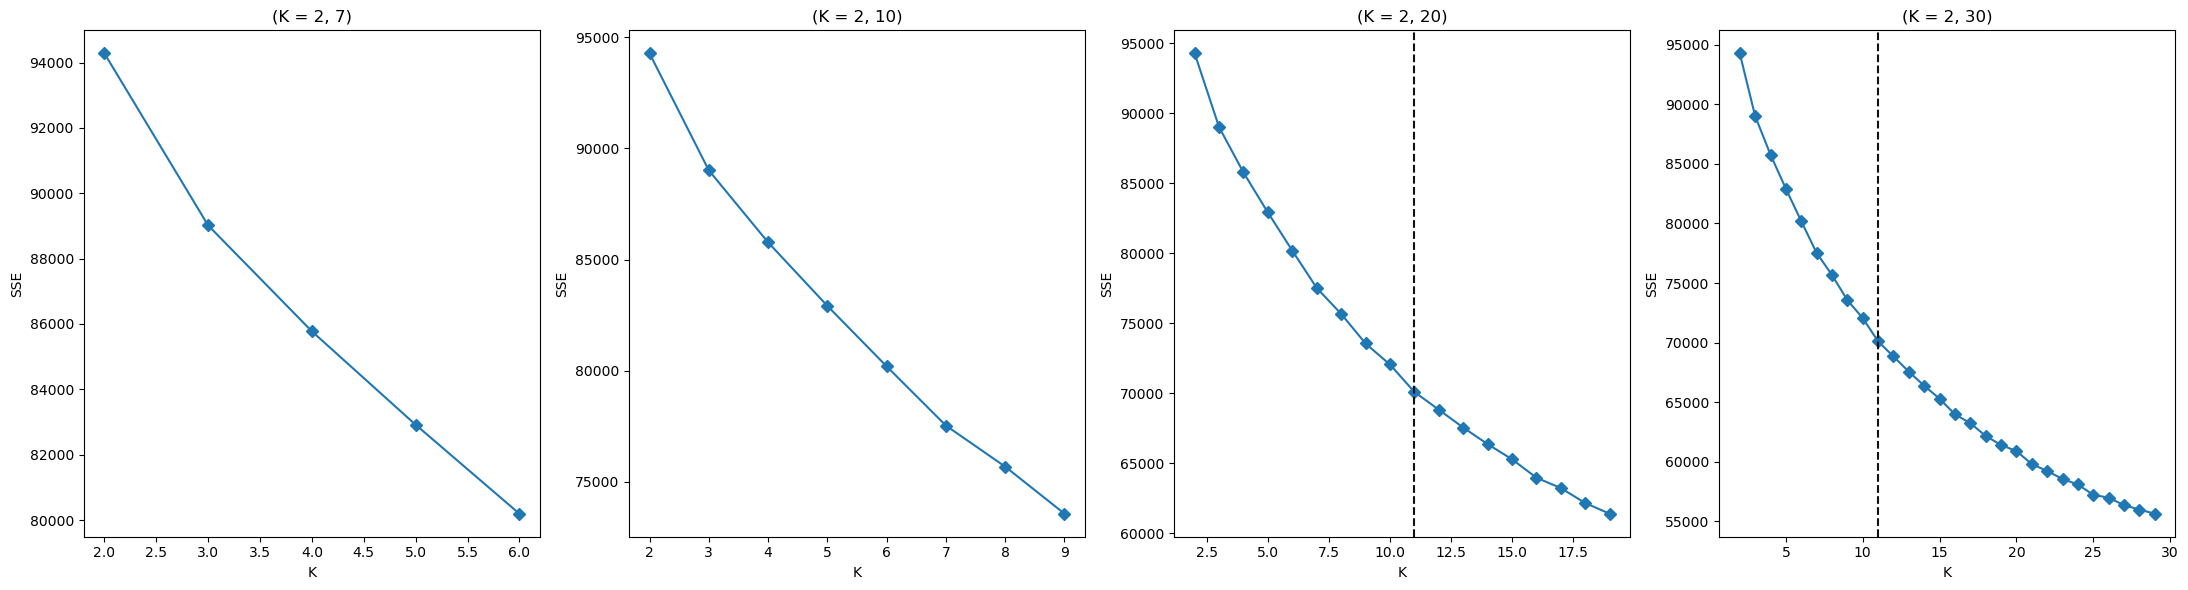

K suggeriti dal metodo elbow: [np.int64(11)]


In [115]:
from yellowbrick.cluster import KElbowVisualizer
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

random_state = 42  # fisso
# Range multipli da testare (2→10, 2→20, 2→30)
k_start = 2
k_max_list = [7,10, 20, 30]

model = KMeans(n_init=10, max_iter=500, random_state=random_state)

fig, axs = plt.subplots(1, len(k_max_list), figsize=(22, 6))

best_Ks = []

for i, k_max in enumerate(k_max_list):
    
    visualizer = KElbowVisualizer(
        model,
        k=(k_start, k_max),
        metric='distortion',    # SSE (inertia)
        timings=False,
        ax=axs[i]
    )

    visualizer.fit(X)  
    
    axs[i].set_title(f'(K = {k_start}, {k_max})')
    axs[i].set_ylabel('SSE')
    axs[i].set_xlabel('K')
    
    elbow_k = visualizer.elbow_value_
    elbow_score = visualizer.elbow_score_

    if elbow_k is not None and elbow_k not in best_Ks:
        best_Ks.append(elbow_k)

plt.tight_layout()
plt.show()
plt.style.use("default") 


print("K suggeriti dal metodo elbow:", best_Ks)


In [116]:
#ciclo di valutazione delle metriche per k da 2 a 10
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn import metrics

results = []

# Valuta k da 2 a 14
for k in range(2, 15):
    kmeans = KMeans(n_clusters=k, n_init=10, max_iter=500, random_state=random_state)
    kmeans.fit(X)
    labels = kmeans.labels_
    
    sse = kmeans.inertia_
    silhouette = silhouette_score(X, labels)
    db = metrics.davies_bouldin_score(X, labels)
    
    results.append([k, sse, silhouette, db])

results_df = pd.DataFrame(results, columns=["K", "SSE", "Silhouette", "DB_score"])
print(results_df)


     K           SSE  Silhouette  DB_score
0    2  94281.724561    0.243863  2.341299
1    3  89016.873566    0.095706  2.722419
2    4  85775.644794    0.062308  2.865087
3    5  82917.614144    0.072767  2.600340
4    6  80194.918293    0.057640  2.508616
5    7  77529.147925    0.064786  2.366766
6    8  75681.181940    0.066812  2.252671
7    9  73564.391715    0.064721  2.226214
8   10  72062.015739    0.061368  2.259862
9   11  70105.939237    0.066892  2.077116
10  12  68837.288625    0.065906  2.114339
11  13  67562.234316    0.072456  2.085111
12  14  66379.143298    0.066629  2.086180


/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_20054/853115581.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=unique_values, y=value_counts, palette="tab10")


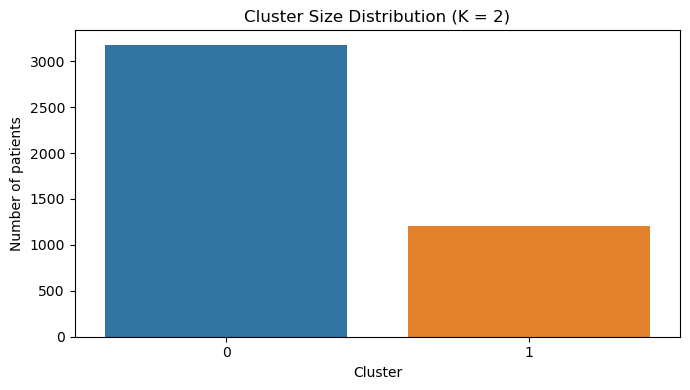

Cluster 0: 3178 pazienti
Cluster 1: 1206 pazienti


In [117]:
from sklearn.cluster import KMeans

k = 2
kmeans = KMeans(n_clusters=k, n_init=10, max_iter=500, random_state=random_state)
kmeans.fit(X)

labels = kmeans.labels_

np.unique(labels, return_counts=True)

# Distribuzione dei pazienti nei cluster
unique_values, value_counts = np.unique(labels, return_counts=True)

plt.figure(figsize=(7, 4))
sns.barplot(x=unique_values, y=value_counts, palette="tab10")

plt.xlabel("Cluster")
plt.ylabel("Number of patients")
plt.title("Cluster Size Distribution (K = 2)")
plt.tight_layout()
plt.show()

# Stampa numeri
for c, n in zip(unique_values, value_counts):
    print(f"Cluster {c}: {n} pazienti")

In [118]:
# centroids
centroids = pd.DataFrame(kmeans.cluster_centers_, columns=final_feature_names)
centroids.index.name = "cluster"
display(centroids)


,number_of_hadm,age,lab_event_count,microbio_test_count,unique_microorganisms_count,unique_procedures_count,max_glucose,max_potassium,max_sodium,max_creatinine,...,abnormal_lab_event_ratio,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction
cluster,,,,,,,,,,,,,,,,,,,,,
0,-0.169412,-0.063959,-0.369726,-0.326908,-0.219668,-0.166836,-0.293545,-0.305541,-0.117822,-0.265522,...,-0.319716,0.326518,0.160742,0.247562,0.047814,0.011953,0.056307,0.007235,0.000315,0.163573
1,0.446937,0.168734,0.975403,0.862440,0.579522,0.440144,0.774423,0.806069,0.310834,0.700494,...,0.843467,0.325311,0.098755,0.421577,0.096266,0.009129,0.042324,0.012448,0.000830,0.113693


In [119]:
#attach labels to original profile dataframe
assert len(labels) == len(profile_df) == len(numeric_df)

dfc = profile_df.copy()
dfc["cluster"] = labels


In [120]:
#means and medians of clusters
means = dfc.groupby("cluster")[numeric_df.columns].mean()
medians = dfc.groupby("cluster")[numeric_df.columns].median()
print("Cluster Means:")
display(means)
print("Cluster Medians:")
display(medians)

Cluster Means:


,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction,number_of_hadm,...,max_ntprobnp,max_ptt,max_inr(pt),max_hemoglobin,max_platelet count,max_white blood cells,max_cholesterol ratio (total/hdl),max_ph,max_pco2,abnormal_lab_event_ratio
cluster,,,,,,,,,,,,,,,,,,,,,
0,0.326306,0.160793,0.247640,0.047829,0.011957,0.056325,0.007237,0.000315,0.163625,1.043738,...,1.063597,2.359318,2.366189,-0.109995,0.325451,0.728040,0.218763,0.064003,0.082536,0.319430
1,0.325871,0.098673,0.421227,0.096186,0.009121,0.042289,0.012438,0.000829,0.113599,1.274461,...,7.169173,4.955531,6.934080,-0.300349,0.531522,1.534946,0.183558,0.546269,1.013267,0.496449


Cluster Medians:


,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction,number_of_hadm,...,max_ntprobnp,max_ptt,max_inr(pt),max_hemoglobin,max_platelet count,max_white blood cells,max_cholesterol ratio (total/hdl),max_ph,max_pco2,abnormal_lab_event_ratio
cluster,,,,,,,,,,,,,,,,,,,,,
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.823077,1.0,-0.05,0.27600,0.633333,0.0,0.0,0.0,0.329205
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,4.106020,3.0,-0.30,0.44069,1.271429,0.0,0.2,0.6,0.494602


In [121]:
# Top features che distinguono i cluster (SOLO feature scalate, in z-score)
z = centroids_z.copy()  # <-- usa la tabella z-score (non la parte ICD)

for c in z.index:
    top_pos = z.loc[c].sort_values(ascending=False).head(8)
    top_neg = z.loc[c].sort_values(ascending=True).head(8)
    print(f"\n=== Cluster {c} (n={np.sum(labels==c)}) ===")
    print("==Più alti della media (z-score):==")
    print(top_pos)
    print("==Più bassi della media (z-score):==")
    print(top_neg)



=== Cluster 0 (n=3178) ===
==Più alti della media (z-score):==
max_hemoglobin                       0.110058
max_cholesterol ratio (total/hdl)    0.020316
age                                 -0.063959
max_troponin t                      -0.093314
max_ntprobnp                        -0.109230
max_sodium                          -0.117822
max_calcium, total                  -0.128533
max_platelet count                  -0.148758
Name: 0, dtype: float64
==Più bassi della media (z-score):==
lab_event_count            -0.369726
max_urea nitrogen          -0.353250
microbio_test_count        -0.326908
abnormal_lab_event_ratio   -0.319716
max_potassium              -0.305541
max_glucose                -0.293545
max_pco2                   -0.286568
max_ph                     -0.271496
Name: 0, dtype: float64

=== Cluster 1 (n=1206) ===
==Più alti della media (z-score):==
lab_event_count             0.975403
max_urea nitrogen           0.931934
microbio_test_count         0.862440
abnormal_lab

In [122]:
# Spread (discriminatività) SOLO sulle feature scalate (z-score)
spread = centroids_z.max(axis=0) - centroids_z.min(axis=0)
display(spread.sort_values(ascending=False).head(15))


lab_event_count                1.345129
max_urea nitrogen              1.285184
microbio_test_count            1.189348
abnormal_lab_event_ratio       1.163184
max_potassium                  1.111610
max_glucose                    1.067969
max_pco2                       1.042586
max_ph                         0.987750
max_creatinine                 0.966016
unique_microorganisms_count    0.799190
max_bicarbonate                0.796675
max_inr(pt)                    0.771537
max_white blood cells          0.765525
max_ptt                        0.723944
number_of_hadm                 0.616349
dtype: float64

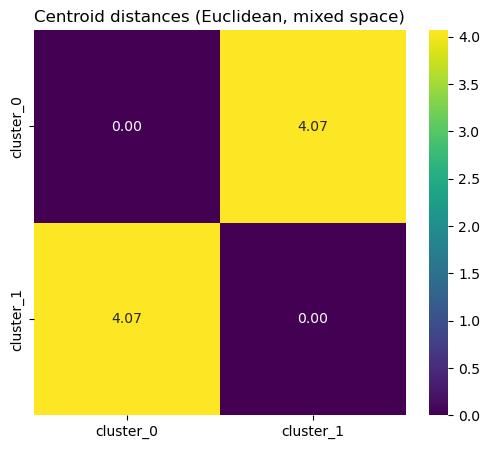

In [123]:
# Centroidi nello spazio in cui KMeans è stato fittato (spazio "misto": [z-score | ICD 0/1])
centers = pd.DataFrame(
    kmeans.cluster_centers_,
    index=[f"cluster_{i}" for i in range(kmeans.n_clusters)],
    columns=final_feature_names
)

C = centers.to_numpy()
dist_matrix = np.linalg.norm(C[:, None, :] - C[None, :, :], axis=2)

plt.figure(figsize=(6, 5))
sns.heatmap(
    dist_matrix,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    xticklabels=centers.index,
    yticklabels=centers.index
)
plt.title("Centroid distances (Euclidean, mixed space)")
plt.show()

# Interpretazione:
# - Ogni cella (i,j) mostra quanto sono distanti i centroidi dei cluster i e j nello spazio usato da KMeans.
# - Qui lo spazio è "misto": feature scalate (z-score) + ICD non scalate (0/1), quindi la distanza riflette entrambe.
# - Valori più grandi => cluster mediamente più separati (centroidi più lontani).
# - Valori piccoli => cluster simili in media (centroidi vicini).


Coppie manuali usate: [('age', 'lab_event_count'), ('age', 'microbio_test_count'), ('lab_event_count', 'unique_procedures_count'), ('max_glucose', 'abnormal_lab_event_ratio')]


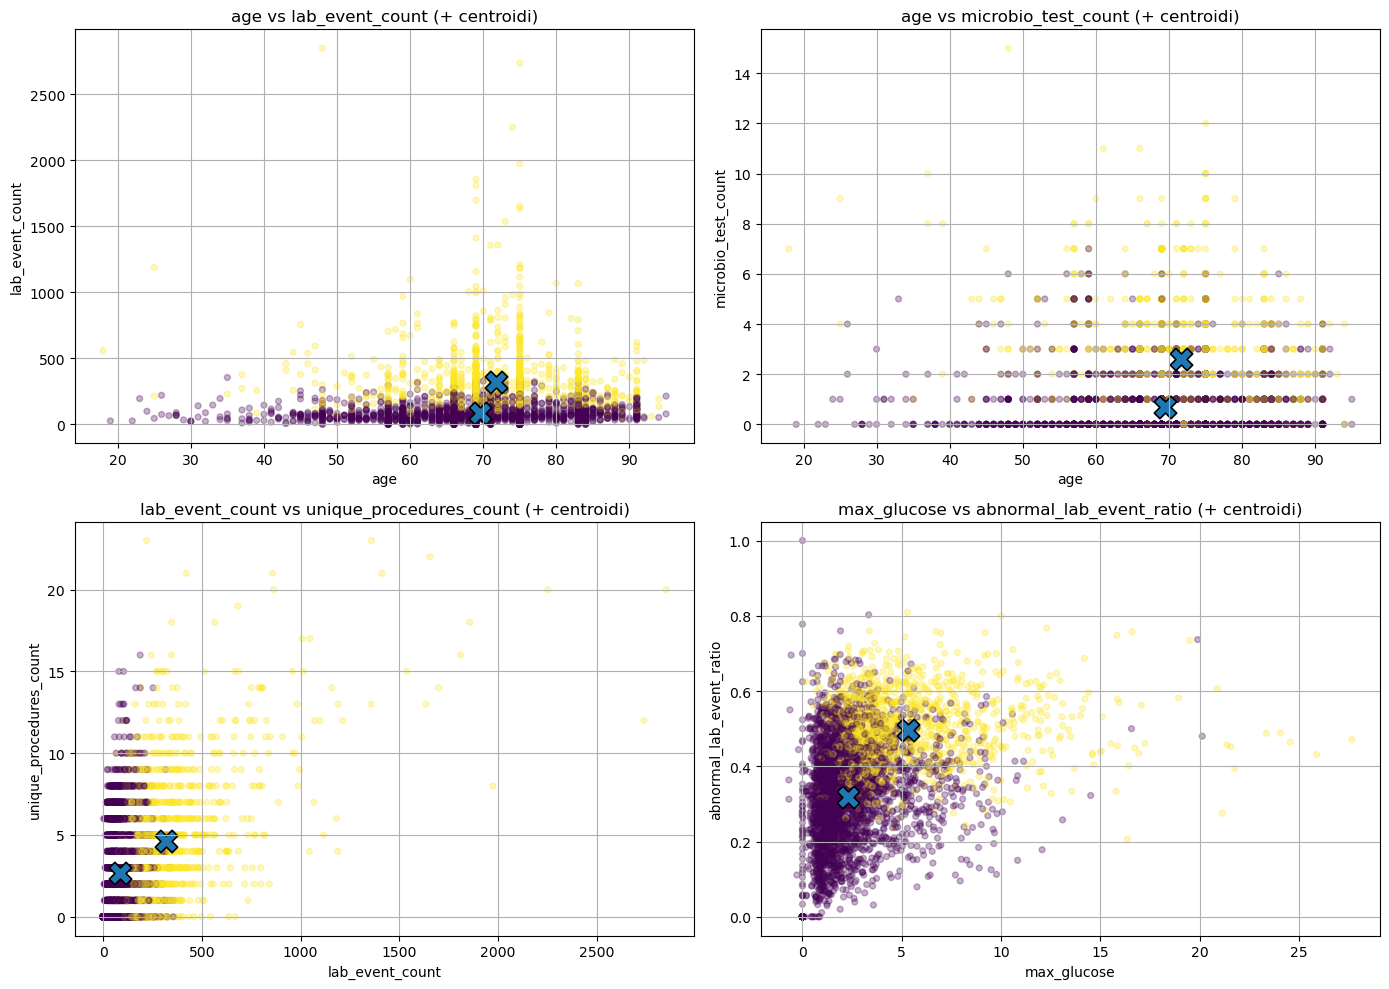

Coppie extra usate: [('max_creatinine', 'max_urea nitrogen'), ('max_creatinine', 'max_potassium'), ('max_inr(pt)', 'max_ptt'), ('max_inr(pt)', 'max_platelet count'), ('lab_event_count', 'abnormal_lab_event_ratio'), ('microbio_test_count', 'unique_microorganisms_count'), ('max_pco2', 'max_ph')]


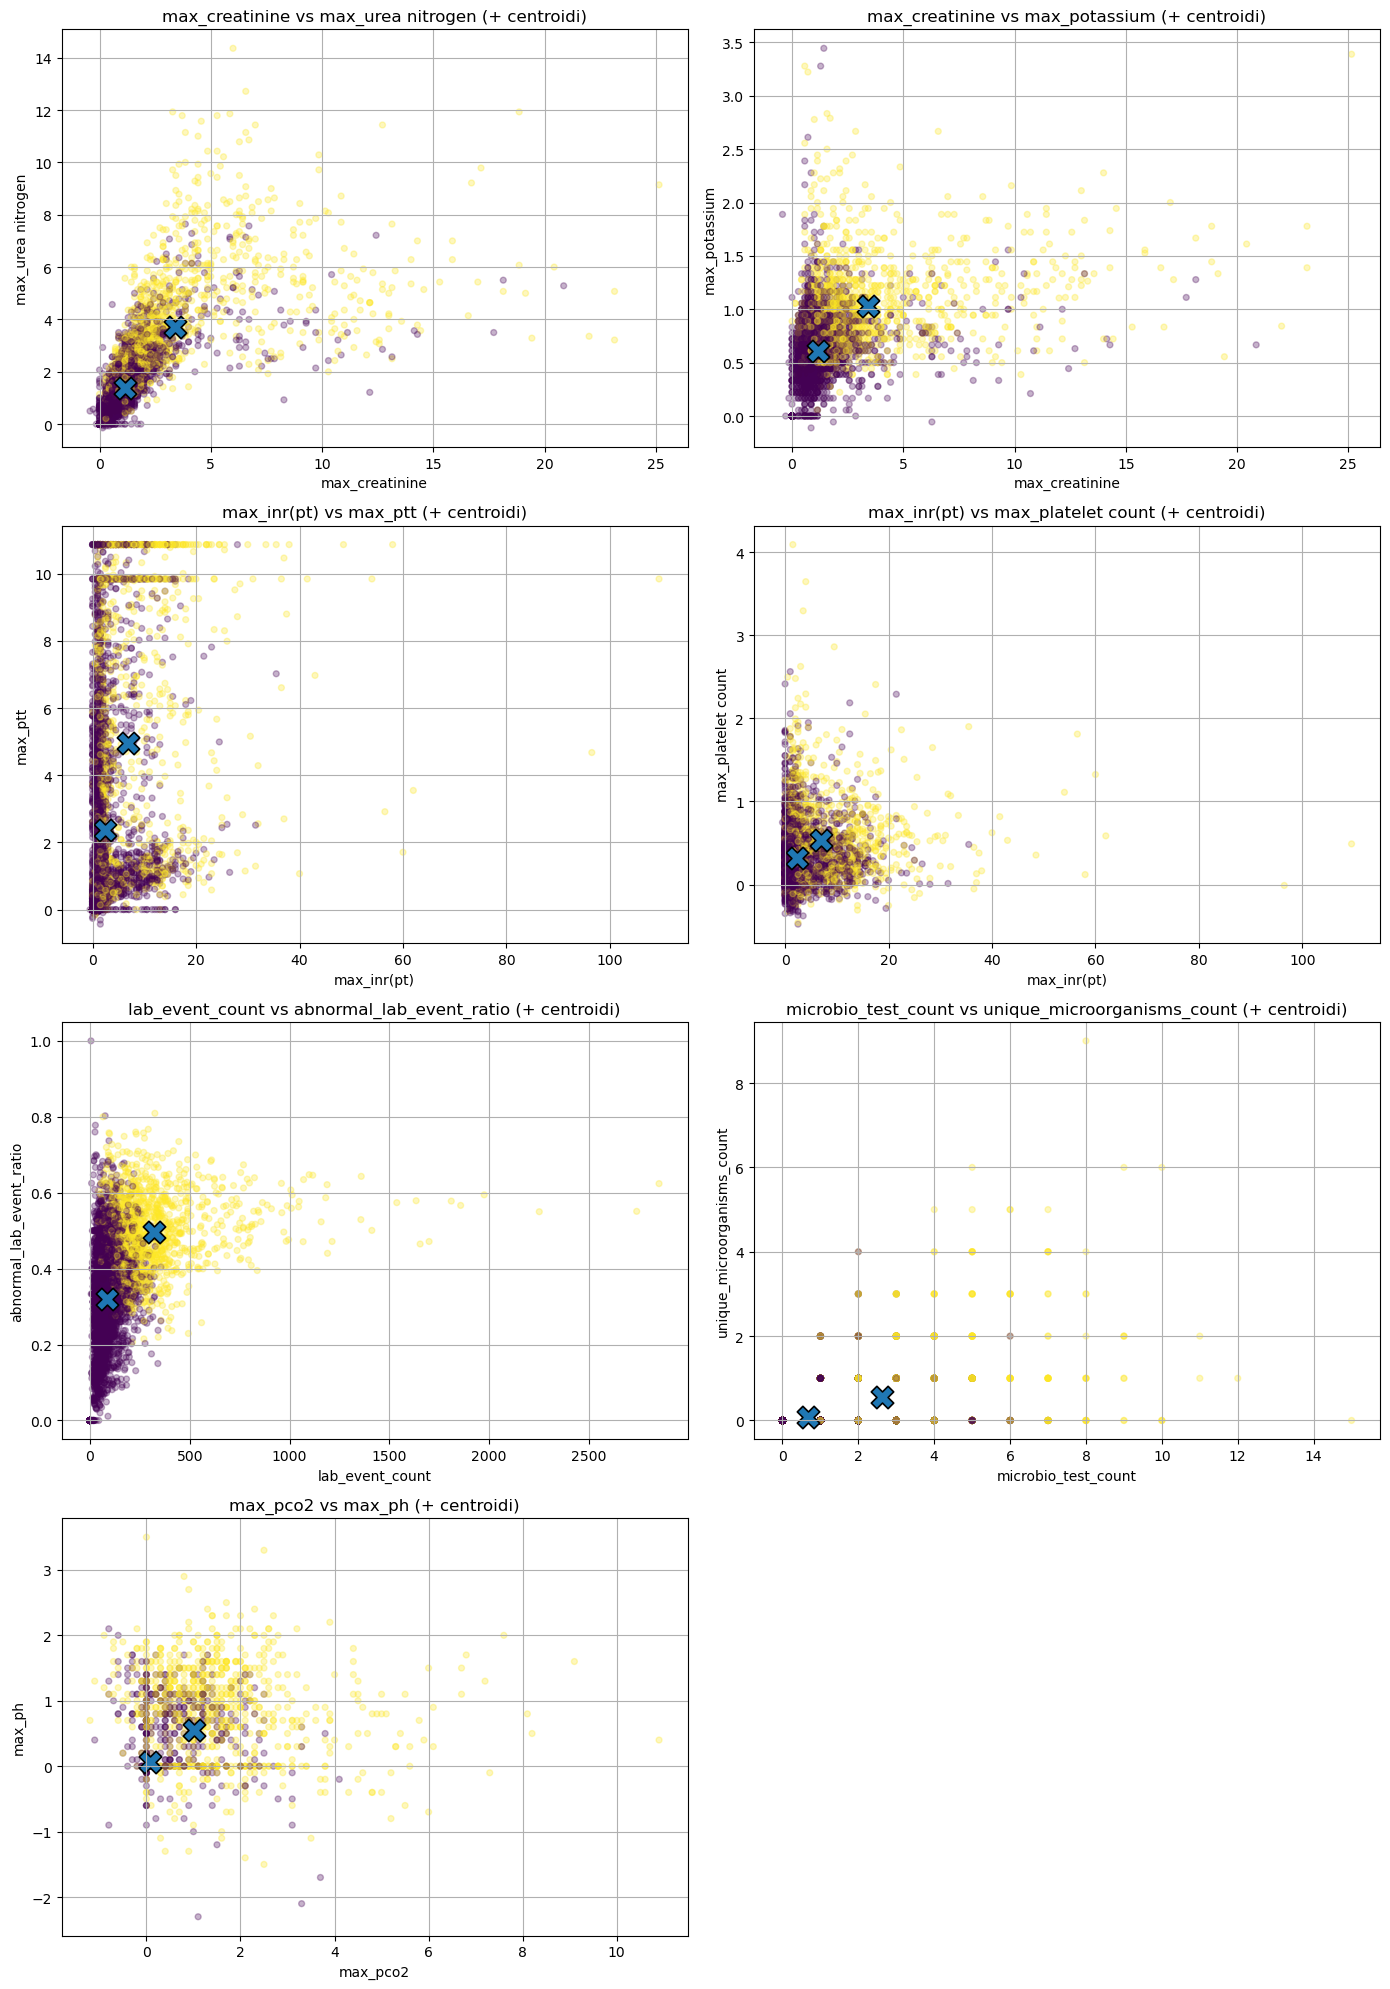

In [124]:
import numpy as np
import matplotlib.pyplot as plt

def scatter_with_centroids(ax, xcol, ycol, df, labels, kmeans, scaler, numeric_cols,
                           s=20, alpha=0.35, centroid_size=260):
    """
    Scatter in scala originale (df) colorato con labels (KMeans su X),
    e centroidi riportati in scala originale SOLO per feature scalate.
    """

    # xcol/ycol devono essere tra le feature scalate, altrimenti non possiamo invertire con scaler
    if xcol not in scale_cols or ycol not in scale_cols:
        raise ValueError(f"Per plottare i centroidi in scala originale, xcol/ycol devono essere in scale_cols. "
                         f"Ricevuto: {xcol}, {ycol}")

    # indici nel blocco scalato (ordine di scale_cols)
    xi = scale_cols.index(xcol)
    yi = scale_cols.index(ycol)

    x = df[xcol].values
    y = df[ycol].values

    # Centroidi: prendo SOLO la parte scalata (prime len(scale_cols) colonne)
    cent_scaled = kmeans.cluster_centers_[:, :len(scale_cols)]

    # Inverto lo scaling per ottenere coordinate centroidi in unità originali
    cx = cent_scaled[:, xi] * scaler.scale_[xi] + scaler.mean_[xi]
    cy = cent_scaled[:, yi] * scaler.scale_[yi] + scaler.mean_[yi]

    sc = ax.scatter(x, y, c=labels, s=s, alpha=alpha)
    ax.scatter(cx, cy, marker="X", s=centroid_size, edgecolor="black", linewidth=1.2)

    ax.set_xlabel(xcol)
    ax.set_ylabel(ycol)
    ax.grid(True)
    return sc


pairs = [
    ("age", "lab_event_count"),
    ("age", "microbio_test_count"),
    ("lab_event_count", "unique_procedures_count"),
    ("max_glucose", "abnormal_lab_event_ratio"),
]

pairs = [(a, b) for a, b in pairs if a in numeric_df.columns and b in numeric_df.columns]
print("Coppie manuali usate:", pairs)

n = len(pairs)
cols = 2
rows = int(np.ceil(n / cols))

fig, axs = plt.subplots(rows, cols, figsize=(14, 5 * rows))
axs = np.array(axs).reshape(-1)

for idx, (xcol, ycol) in enumerate(pairs):
    scatter_with_centroids(
        axs[idx], xcol, ycol,
        df=numeric_df, labels=labels,
        kmeans=kmeans, scaler=scaler, numeric_cols=numeric_cols,
        s=18, alpha=0.30, centroid_size=260
    )
    axs[idx].set_title(f"{xcol} vs {ycol} (+ centroidi)")

for j in range(idx + 1, len(axs)):
    axs[j].axis("off")

plt.tight_layout()
plt.show()

pairs_extra = [
    ("max_creatinine", "max_urea nitrogen"),
    ("max_creatinine", "max_potassium"),
    ("max_inr(pt)", "max_ptt"),
    ("max_inr(pt)", "max_platelet count"),
    ("lab_event_count", "abnormal_lab_event_ratio"),
    ("microbio_test_count", "unique_microorganisms_count"),
    ("max_pco2", "max_ph"),

]

pairs_extra = [(a, b) for a, b in pairs_extra if a in numeric_df.columns and b in numeric_df.columns]
print("Coppie extra usate:", pairs_extra)

n = len(pairs_extra)
cols = 2
rows = int(np.ceil(n / cols))

fig, axs = plt.subplots(rows, cols, figsize=(14, 5 * rows))
axs = np.array(axs).reshape(-1)

for idx, (xcol, ycol) in enumerate(pairs_extra):
    scatter_with_centroids(
        axs[idx], xcol, ycol,
        df=numeric_df, labels=labels,
        kmeans=kmeans, scaler=scaler, numeric_cols=numeric_cols,
        s=18, alpha=0.30, centroid_size=260
    )
    axs[idx].set_title(f"{xcol} vs {ycol} (+ centroidi)")

for j in range(idx + 1, len(axs)):
    axs[j].axis("off")

plt.tight_layout()
plt.show()



[Manuali + nuove] Triple usate: [('age', 'lab_event_count', 'microbio_test_count'), ('lab_event_count', 'unique_procedures_count', 'abnormal_lab_event_ratio'), ('max_glucose', 'abnormal_lab_event_ratio', 'lab_event_count'), ('max_troponin t', 'max_ntprobnp', 'lab_event_count'), ('max_pco2', 'max_ph', 'max_potassium'), ('max_inr(pt)', 'max_ptt', 'max_white blood cells'), ('max_creatinine', 'max_urea nitrogen', 'lab_event_count')]


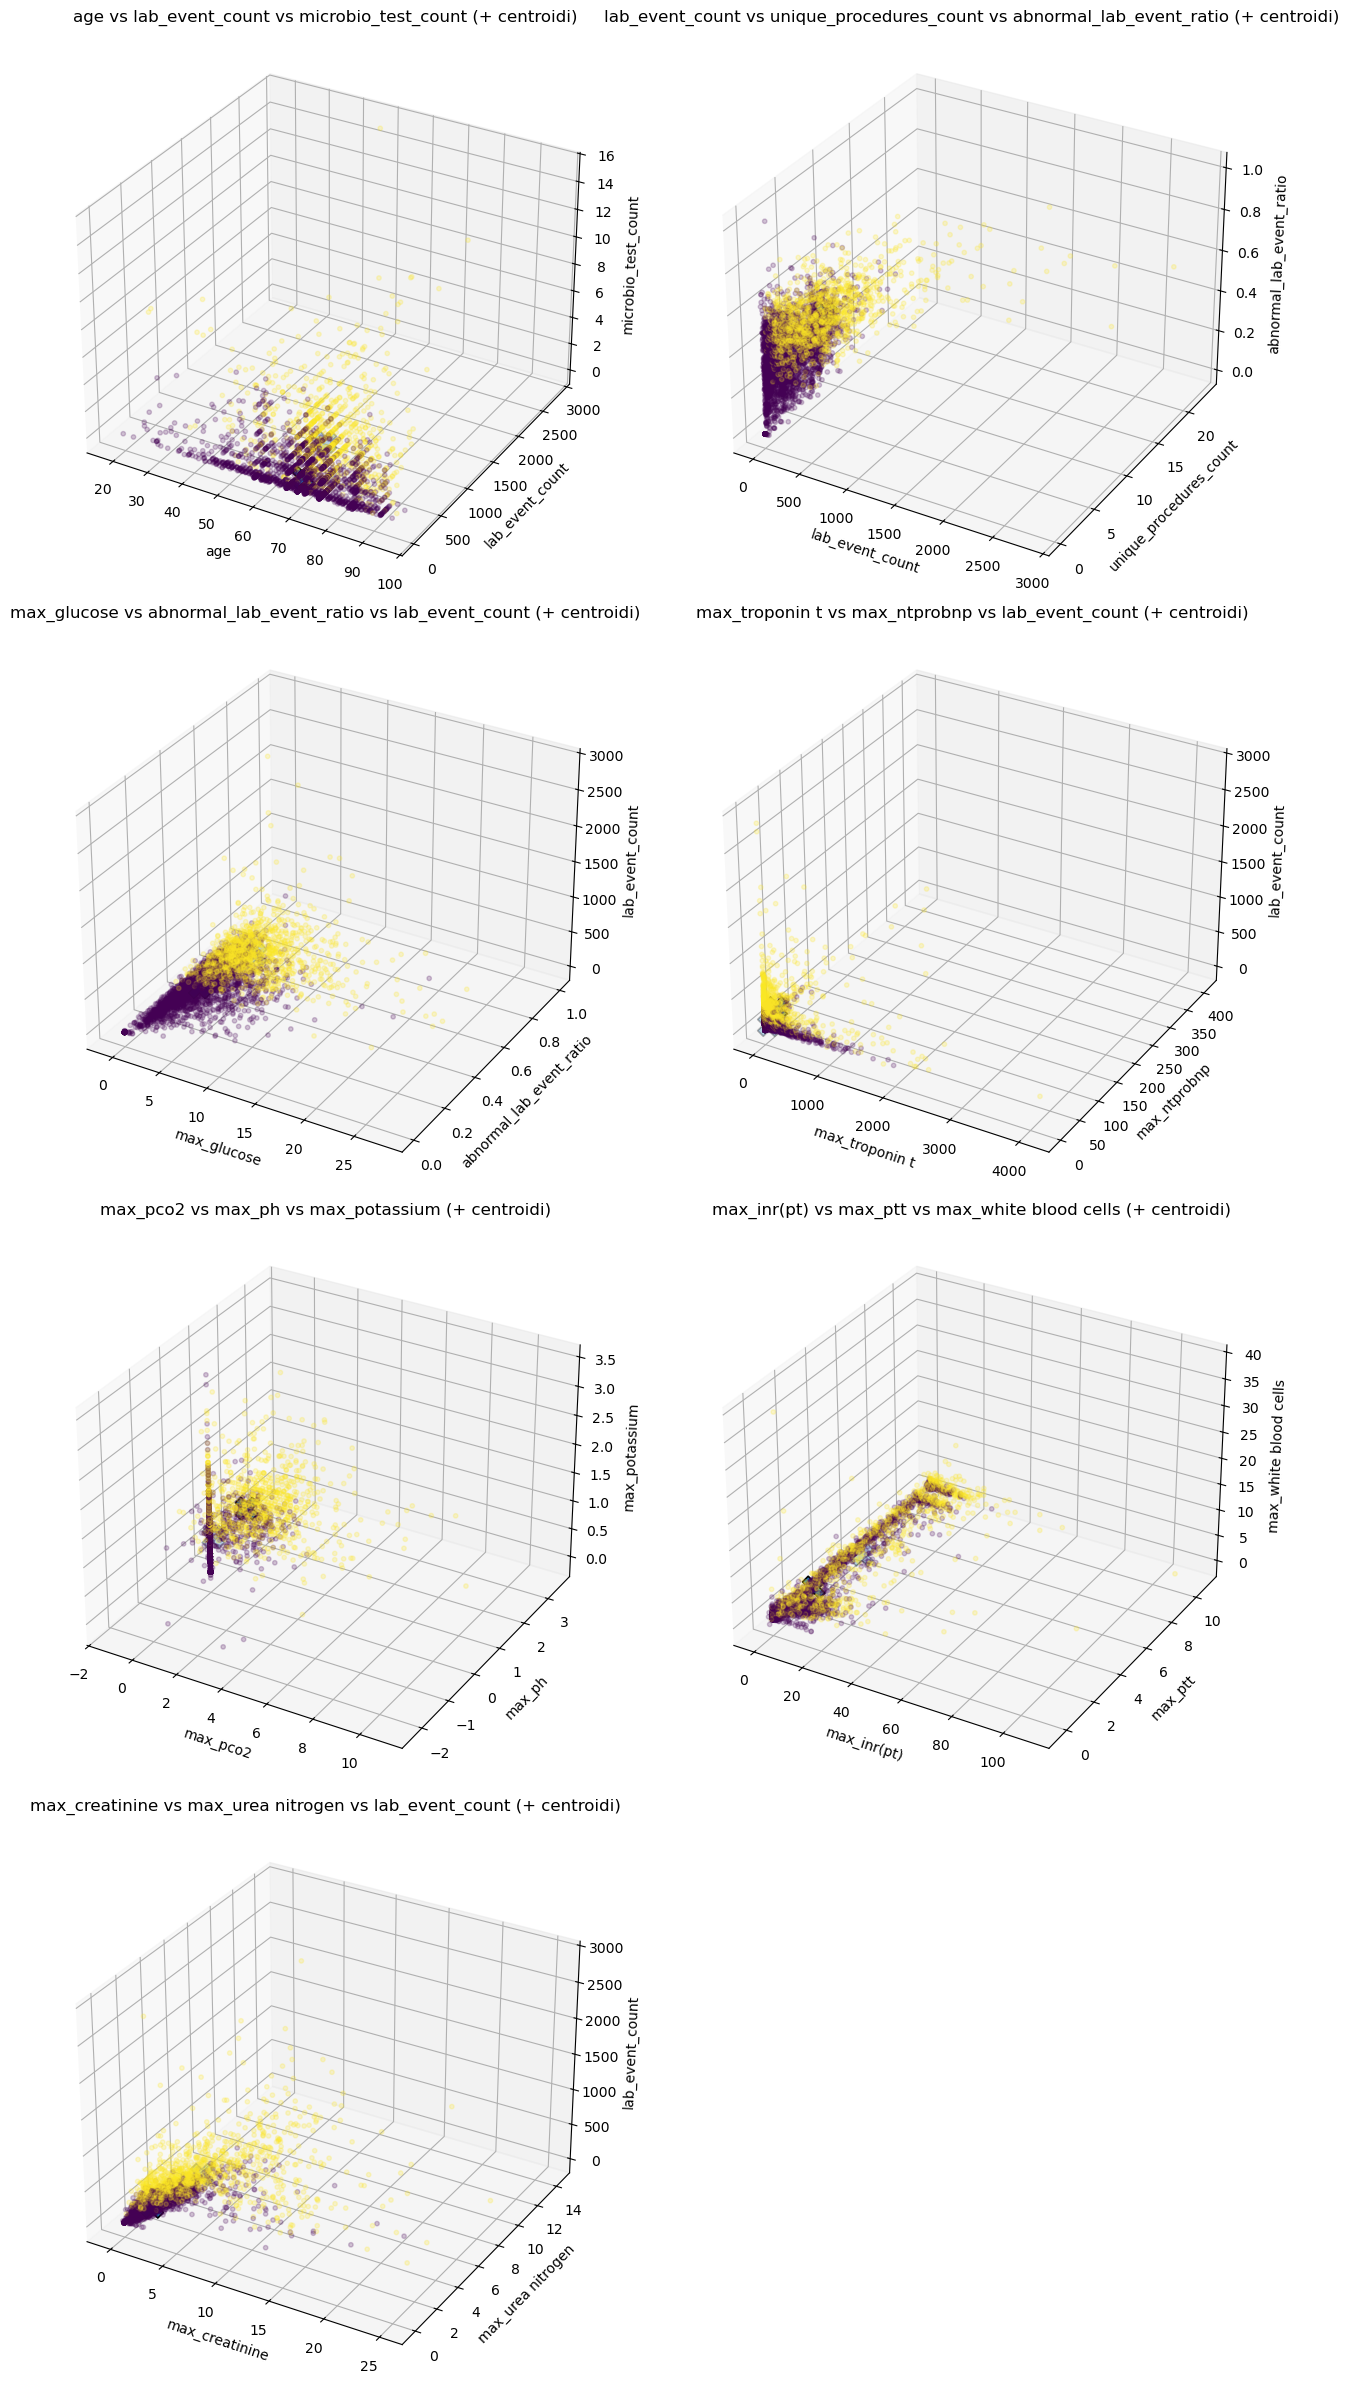

[Extra + nuove] Triple usate: [('max_creatinine', 'max_urea nitrogen', 'max_potassium'), ('max_inr(pt)', 'max_ptt', 'max_platelet count'), ('max_creatinine', 'max_potassium', 'abnormal_lab_event_ratio'), ('max_creatinine', 'max_glucose', 'abnormal_lab_event_ratio'), ('max_white blood cells', 'max_platelet count', 'lab_event_count')]


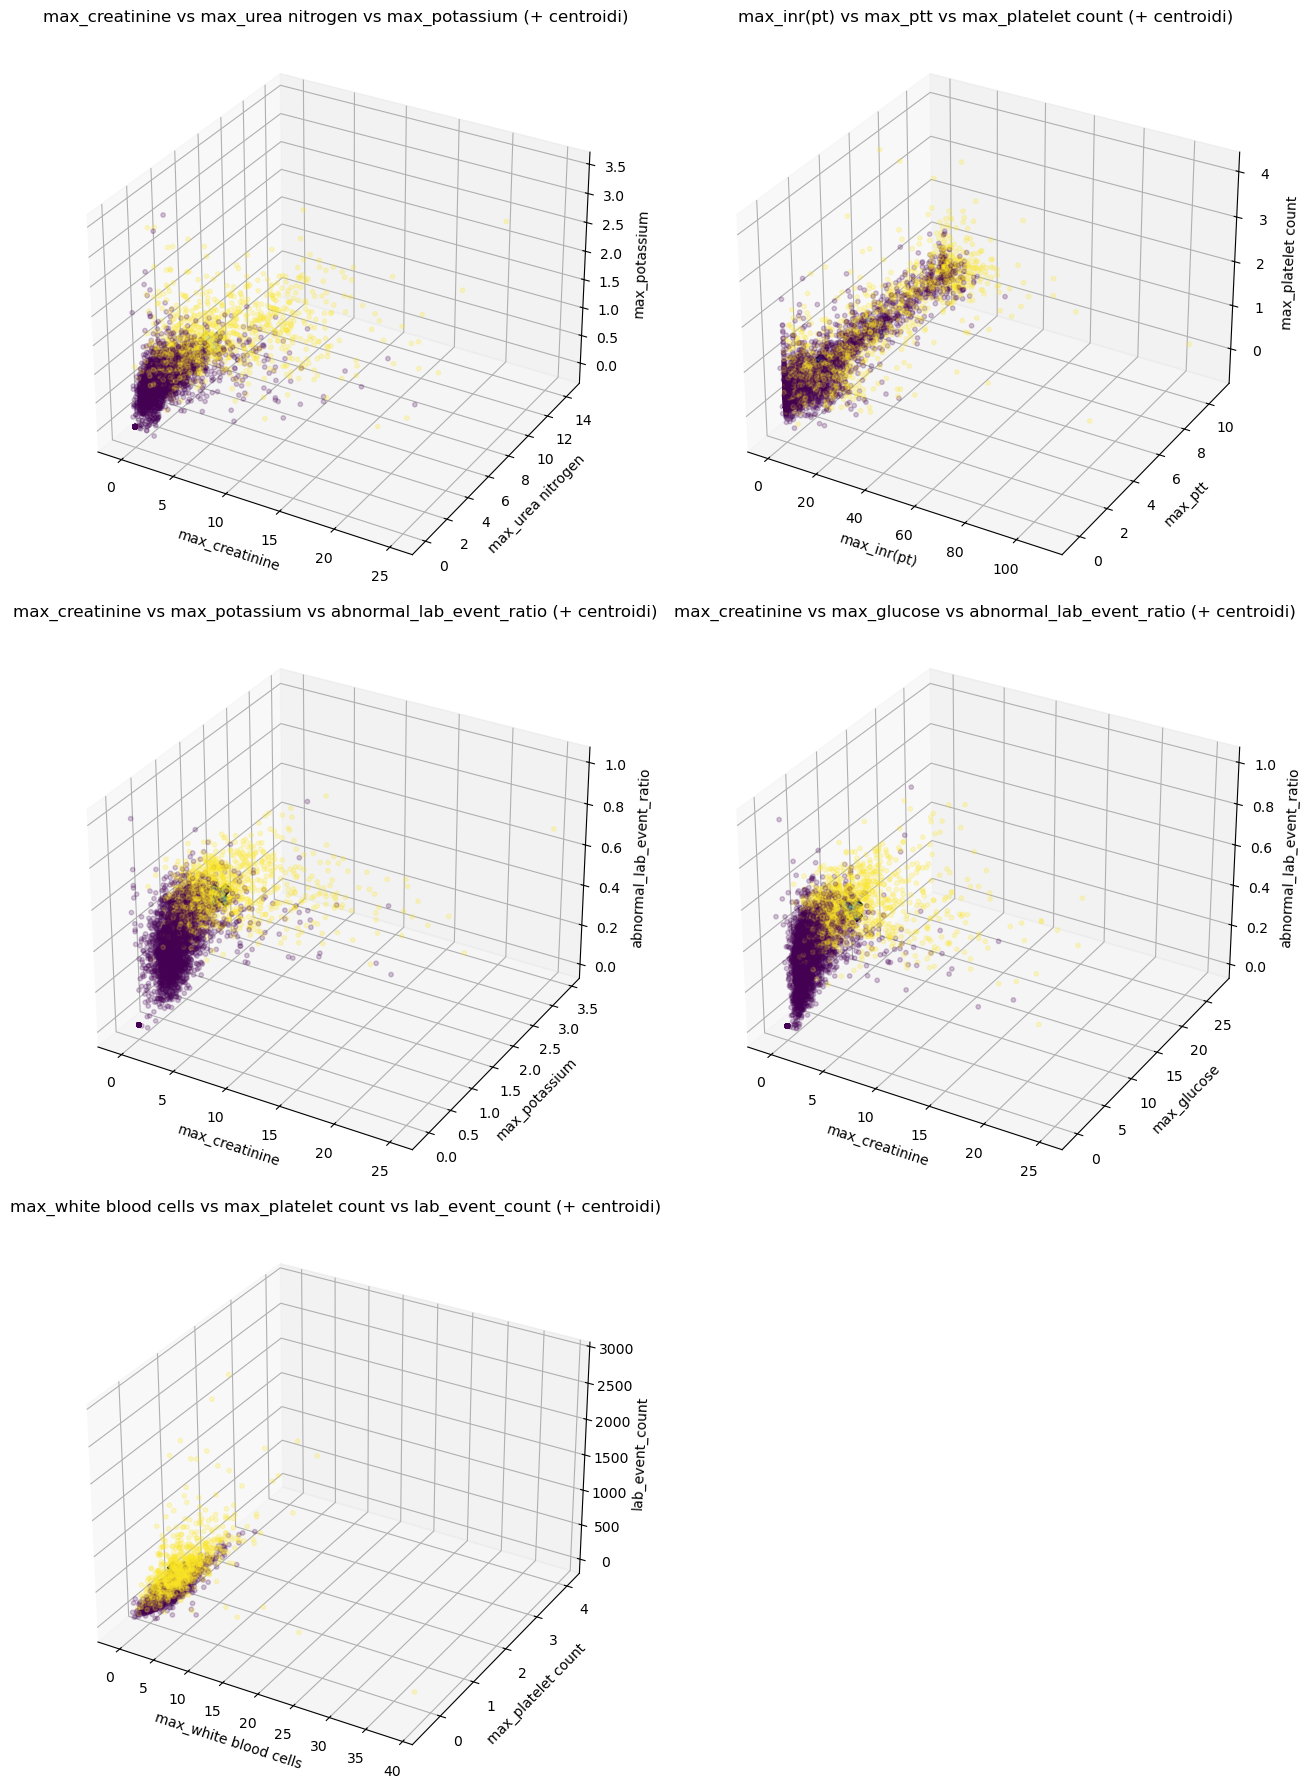

In [125]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

# =============================================================================
# 3D Scatter + Centroidi (corretto per X "misto": [scaled | ICD raw])
# - Plotta i punti in scala originale (numeric_df)
# - Colora per cluster
# - Plotta i centroidi riportati in scala originale SOLO per le feature scalate
# =============================================================================

def scatter3d_with_centroids(ax, xcol, ycol, zcol, df, labels, kmeans, scaler,
                             scale_cols, s=10, alpha=0.22, centroid_size=260):
    """
    Scatter 3D in scala originale (df) colorato con labels (KMeans su X misto),
    con centroidi riportati in scala originale via scaler (solo per feature scalate).

    Nota: xcol, ycol, zcol devono essere in scale_cols.
    """

    # Verifica che le colonne siano nel blocco scalato
    for col in (xcol, ycol, zcol):
        if col not in scale_cols:
            raise ValueError(
                f"'{col}' non è in scale_cols: per i centroidi posso invertire lo scaling "
                f"solo sulle feature scalate."
            )

    # Indici nel blocco scalato (ordine scale_cols)
    xi = scale_cols.index(xcol)
    yi = scale_cols.index(ycol)
    zi = scale_cols.index(zcol)

    # Dati (scala originale)
    x = df[xcol].values
    y = df[ycol].values
    z = df[zcol].values

    # Centroidi: prendo SOLO la parte scalata (prime len(scale_cols) colonne)
    cent_scaled = kmeans.cluster_centers_[:, :len(scale_cols)]

    # Inverto lo scaling -> coordinate centroidi in unità originali
    cx = cent_scaled[:, xi] * scaler.scale_[xi] + scaler.mean_[xi]
    cy = cent_scaled[:, yi] * scaler.scale_[yi] + scaler.mean_[yi]
    cz = cent_scaled[:, zi] * scaler.scale_[zi] + scaler.mean_[zi]

    ax.scatter(x, y, z, c=labels, s=s, alpha=alpha)
    ax.scatter(cx, cy, cz, marker="X", s=centroid_size, edgecolor="black", linewidth=1.2)

    ax.set_xlabel(xcol)
    ax.set_ylabel(ycol)
    ax.set_zlabel(zcol)
    ax.set_title(f"{xcol} vs {ycol} vs {zcol} (+ centroidi)")
    ax.grid(True)


def plot_triples_3d(triples, df, labels, kmeans, scaler, scale_cols, title_prefix=""):
    """
    Plotta una lista di triple 3D in griglia 2 colonne, spegnendo subplot vuoti.
    """
    triples = [(a, b, c) for a, b, c in triples
               if a in df.columns and b in df.columns and c in df.columns]

    # Tieni solo triple dove tutte le colonne sono scalate (necessario per centroidi)
    triples = [(a, b, c) for a, b, c in triples
               if a in scale_cols and b in scale_cols and c in scale_cols]

    print(f"{title_prefix} Triple usate:", triples)

    n = len(triples)
    if n == 0:
        print("Nessuna triple valida da plottare.")
        return

    cols = 2
    rows = int(np.ceil(n / cols))

    fig = plt.figure(figsize=(14, 6 * rows))

    for i, (xcol, ycol, zcol) in enumerate(triples, start=1):
        ax = fig.add_subplot(rows, cols, i, projection="3d")
        scatter3d_with_centroids(
            ax, xcol, ycol, zcol,
            df=df, labels=labels,
            kmeans=kmeans, scaler=scaler,
            scale_cols=scale_cols,
            s=10, alpha=0.22, centroid_size=260
        )

    # Spegni subplot vuoti
    for j in range(n + 1, rows * cols + 1):
        ax = fig.add_subplot(rows, cols, j, projection="3d")
        ax.set_axis_off()

    plt.tight_layout()
    plt.show()


# =============================================================================
# Triple 3D (manuali + extra) + nuove triple consigliate
# =============================================================================

triples = [
    # intensità test / attività clinica
    ("age", "lab_event_count", "microbio_test_count"),
    ("lab_event_count", "unique_procedures_count", "abnormal_lab_event_ratio"),
    ("max_glucose", "abnormal_lab_event_ratio", "lab_event_count"),

    # nuove triple consigliate (legame clinico e spesso correlate alle ICD macro)
    ("max_troponin t", "max_ntprobnp", "lab_event_count"),            # ischemia/scompenso + intensità
    ("max_pco2", "max_ph", "max_potassium"),                          # resp/acidosi + elettroliti (aritmie/arresto)
    ("max_inr(pt)", "max_ptt", "max_white blood cells"),              # coagulazione + infiammazione
    ("max_creatinine", "max_urea nitrogen", "lab_event_count"),       # rene + intensità
]

plot_triples_3d(
    triples,
    df=numeric_df,
    labels=labels,
    kmeans=kmeans,
    scaler=scaler,
    scale_cols=scale_cols,
    title_prefix="[Manuali + nuove]"
)


triples_extra = [
    ("max_creatinine", "max_urea nitrogen", "max_potassium"),
    ("max_inr(pt)", "max_ptt", "max_platelet count"),
    ("max_creatinine", "max_potassium", "abnormal_lab_event_ratio"),

    # altre combinazioni utili
    ("max_creatinine", "max_glucose", "abnormal_lab_event_ratio"),    # metabolico+rene+anomalie
    ("max_white blood cells", "max_platelet count", "lab_event_count")# infiammazione/emato + intensità
]

plot_triples_3d(
    triples_extra,
    df=numeric_df,
    labels=labels,
    kmeans=kmeans,
    scaler=scaler,
    scale_cols=scale_cols,
    title_prefix="[Extra + nuove]"
)


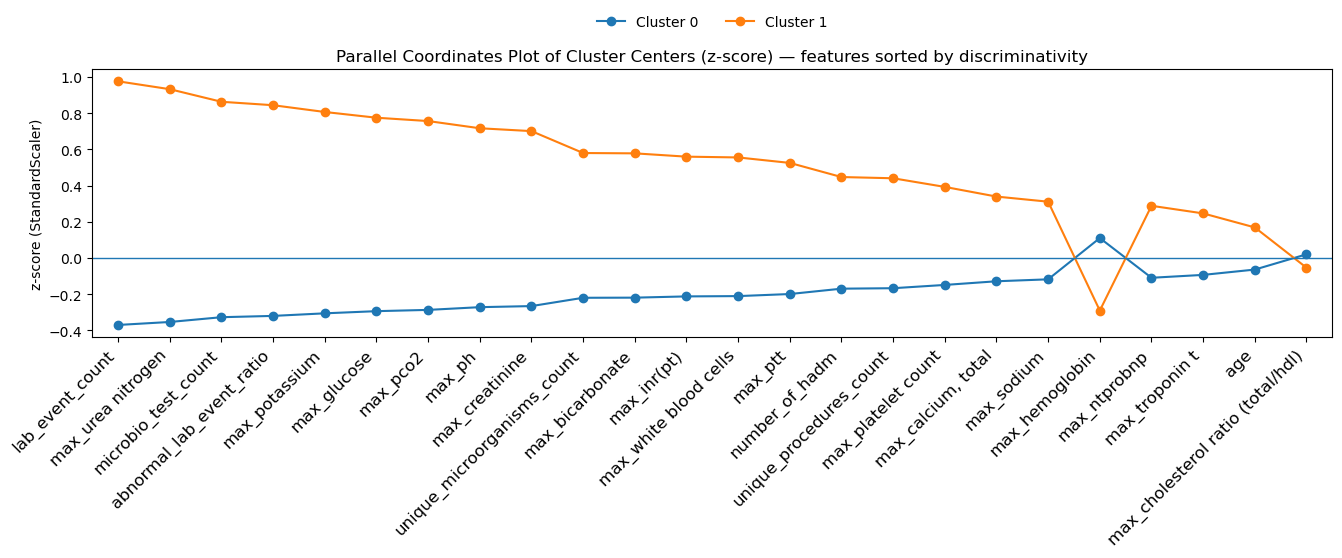

In [126]:
import numpy as np
import matplotlib.pyplot as plt

# Centroidi: prendo SOLO la parte scalata (z-score)
p_scaled = len(scale_cols)
centers_z = kmeans.cluster_centers_[:, :p_scaled]   # (k, p_scaled)
cols = list(scale_cols)

# discriminatività = spread tra centroidi (in z-score)
spread = centers_z.max(axis=0) - centers_z.min(axis=0)
order = np.argsort(-spread)

centers_ord = centers_z[:, order]
cols_ord = [cols[i] for i in order]

N = centers_ord.shape[1]
x = np.arange(N)

plt.figure(figsize=(16, 4))
for i in range(centers_ord.shape[0]):
    plt.plot(x, centers_ord[i], marker='o', label=f'Cluster {i}')

plt.axhline(0, linewidth=1)  # 0 = media globale (solo per z-score)
plt.xticks(x, cols_ord, fontsize=12, rotation=45, ha='right')
plt.xlim(-0.5, N - 0.5)
plt.ylabel("z-score (StandardScaler)")

plt.legend(loc='upper center', bbox_to_anchor=(0.5, 1.25),
           ncol=centers_ord.shape[0], frameon=False)

plt.subplots_adjust(top=0.78)
plt.title("Parallel Coordinates Plot of Cluster Centers (z-score) — features sorted by discriminativity")
plt.show()


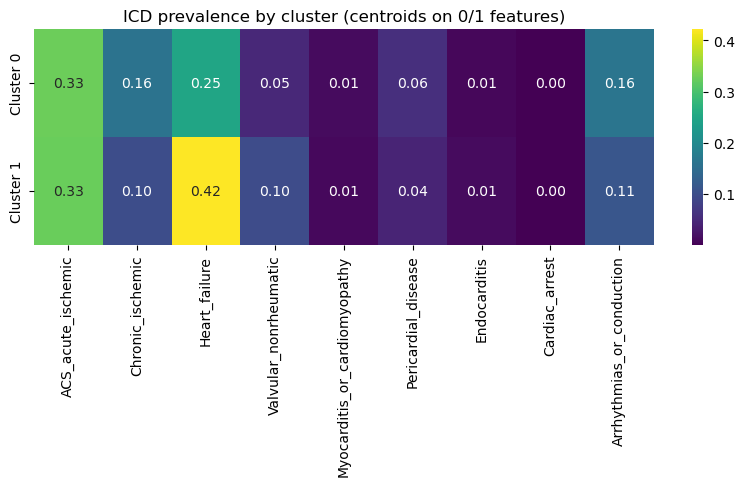

In [127]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

centers_icd = pd.DataFrame(
    kmeans.cluster_centers_[:, p_scaled:],
    index=[f"Cluster {i}" for i in range(kmeans.n_clusters)],
    columns=icd_cols_present
)

plt.figure(figsize=(10, 2.8))
sns.heatmap(centers_icd, annot=True, fmt=".2f", cmap="viridis")
plt.title("ICD prevalence by cluster (centroids on 0/1 features)")
plt.ylabel("")
plt.show()


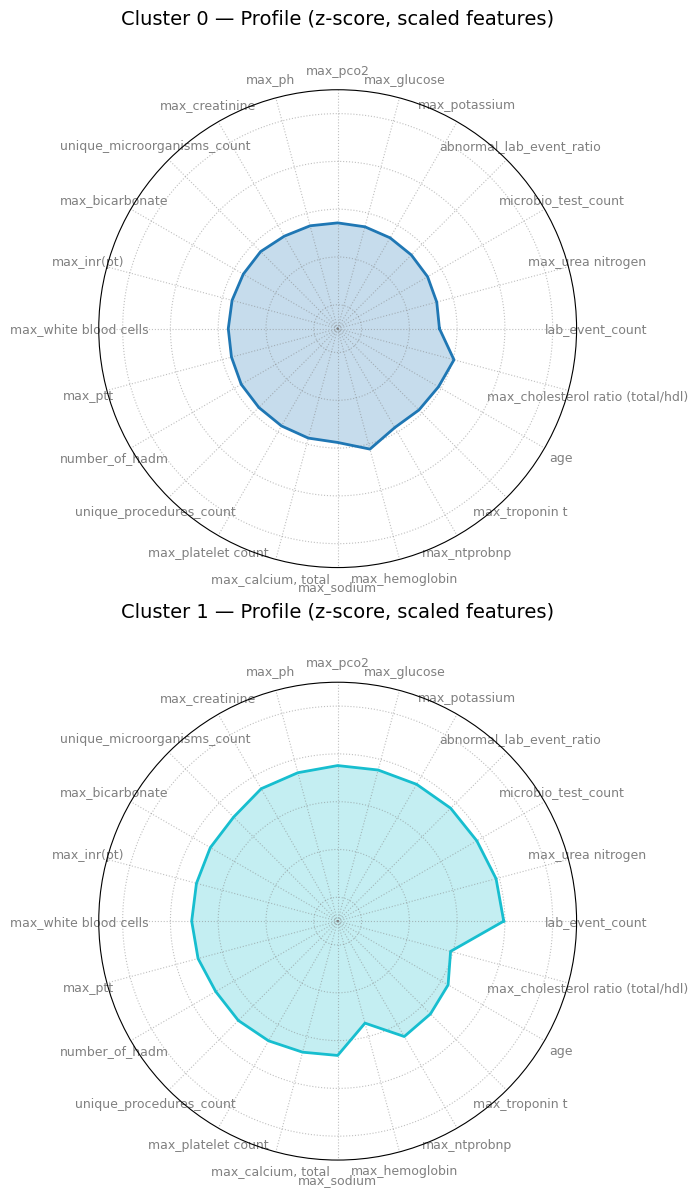

In [128]:
from math import pi
import numpy as np
import matplotlib.pyplot as plt

# --- usa SOLO la parte scalata (z-score) ---
p_scaled = len(scale_cols)
centers_np = kmeans.cluster_centers_[:, :p_scaled]   # (k, p_scaled)
features_labels = list(scale_cols)

# Ordina le feature per discriminatività (spread tra centroidi)
spread = centers_np.max(axis=0) - centers_np.min(axis=0)
order = np.argsort(-spread)
centers_np = centers_np[:, order]
features_labels = [features_labels[i] for i in order]

N = centers_np.shape[1]
colors = plt.cm.tab10(np.linspace(0, 1, centers_np.shape[0]))

plt.figure(figsize=(12, 12))

for cluster_id in range(centers_np.shape[0]):
    values = centers_np[cluster_id].tolist()
    values += values[:1]  # chiudi poligono

    angles = [n / float(N) * 2*pi for n in range(N)]
    angles += angles[:1]

    ax = plt.subplot(centers_np.shape[0], 1, cluster_id + 1, polar=True)

    ax.plot(angles, values, linewidth=2, color=colors[cluster_id])
    ax.fill(angles, values, alpha=0.25, color=colors[cluster_id])

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(features_labels, size=9, color="grey")

    # stessa scala radiale per confrontare davvero i cluster
    ax.set_ylim(-2.5, 2.5)

    ax.grid(color="grey", linestyle="dotted", alpha=0.5)
    ax.set_yticklabels([])
    ax.set_title(f"Cluster {cluster_id} — Profile (z-score, scaled features)", size=14, y=1.12)

plt.tight_layout()
plt.show()


/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_20054/2495088612.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Cluster", y=var, data=df_box, palette="tab10")
/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_20054/2495088612.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Cluster", y=var, data=df_box, palette="tab10")
/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_20054/2495088612.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Cluster", y=var, data=df_box, palette="tab10")


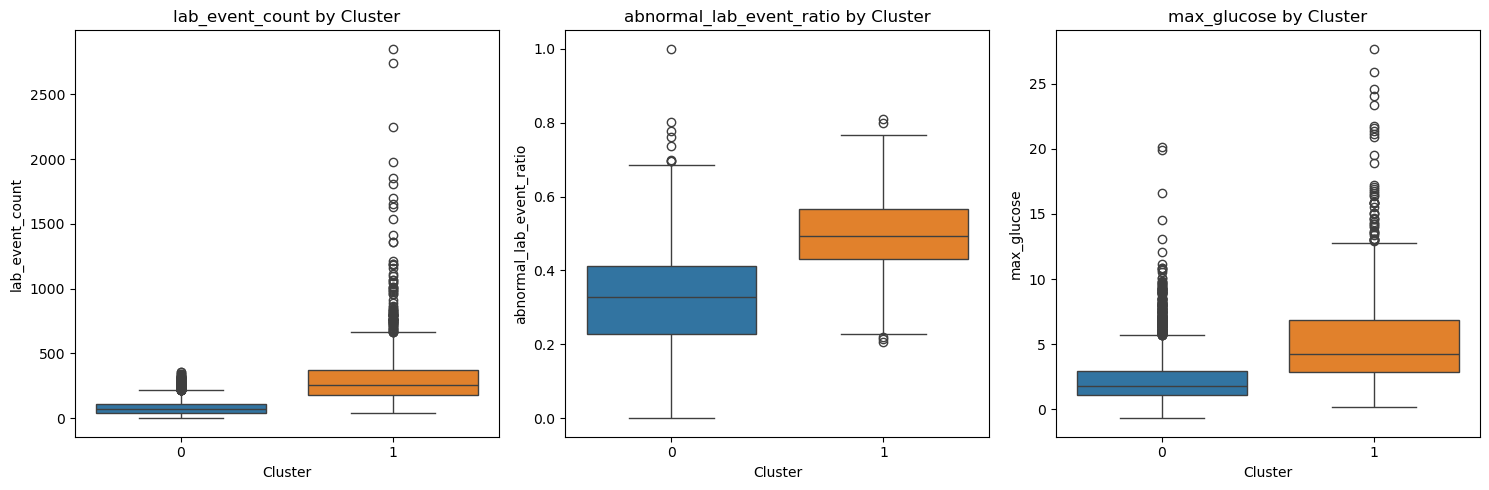

In [129]:
import seaborn as sns
import matplotlib.pyplot as plt

# Creiamo un DataFrame con i dati originali e il cluster assegnato
df_box = numeric_df.copy()
df_box["Cluster"] = labels

vars_to_plot = [
    "lab_event_count",
    "abnormal_lab_event_ratio",
    "max_glucose",
]

plt.figure(figsize=(15, 5))

for i, var in enumerate(vars_to_plot, 1):
    plt.subplot(1, len(vars_to_plot), i)
    sns.boxplot(x="Cluster", y=var, data=df_box, palette="tab10")
    plt.title(f"{var} by Cluster")
    plt.xlabel("Cluster")
    plt.ylabel(var)

plt.tight_layout()
plt.show()


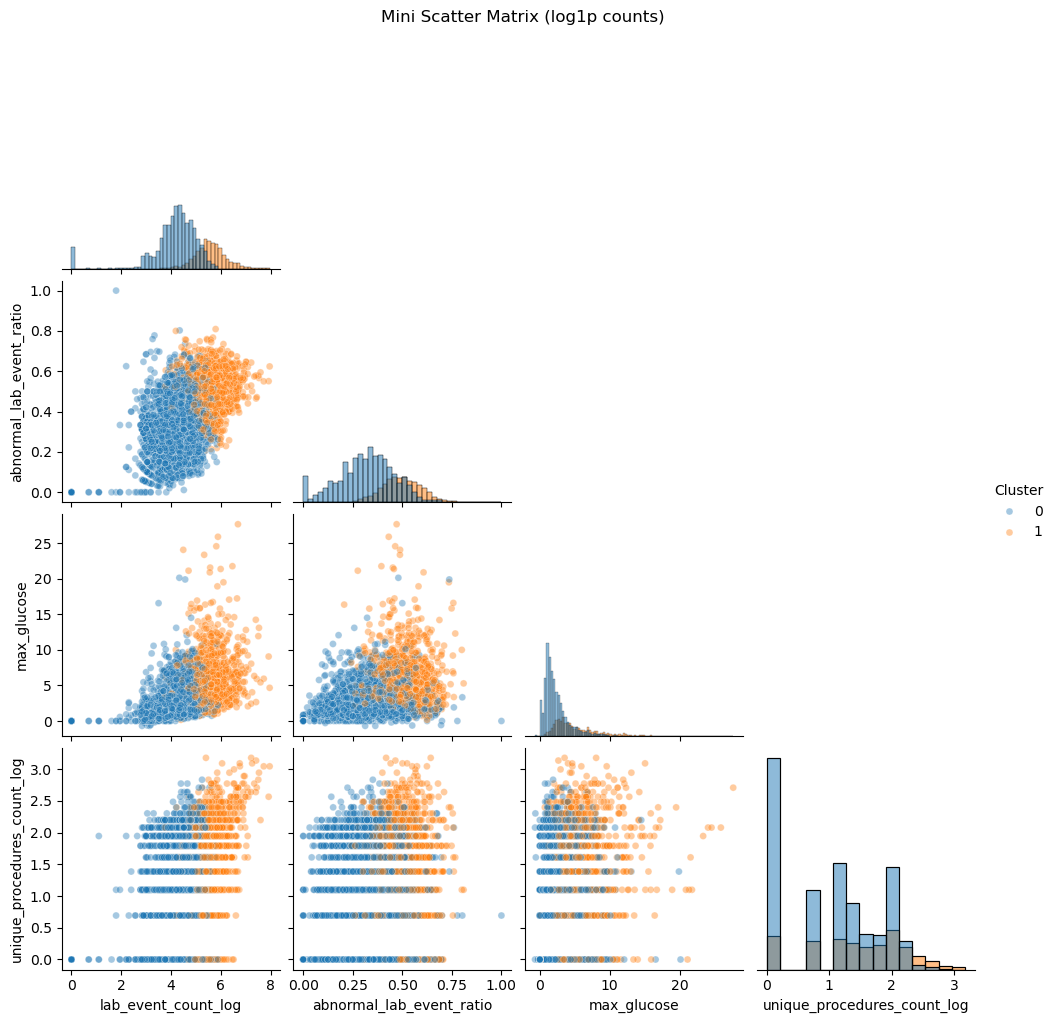

In [130]:
df_scatter = numeric_df.copy()
df_scatter["Cluster"] = labels

df_scatter["lab_event_count_log"] = np.log1p(df_scatter["lab_event_count"])
df_scatter["unique_procedures_count_log"] = np.log1p(df_scatter["unique_procedures_count"])

vars_scatter = [
    "lab_event_count_log",
    "abnormal_lab_event_ratio",
    "max_glucose",
    "unique_procedures_count_log"
]

sns.pairplot(
    df_scatter[vars_scatter + ["Cluster"]],
    hue="Cluster",
    palette="tab10",
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.4, "s": 25}
)

plt.suptitle("Mini Scatter Matrix (log1p counts)", y=1.02)
plt.show()
